# LOGISMART — Evidencias de modelado y evaluación (H4–H5)

Este notebook **documenta e interpreta los resultados** producidos por los módulos de `src/`; no entrena modelos ni recalcula SHAP. Su objetivo es servir como evidencia académica del proceso CRISP-DM.

**Fuente de los resultados:** `output/resultados/*.json` y `output/graficos/*.png`, generados por los comandos `python main.py --proceso entrenar`, `evaluar` y `explicar`.

**Alcance:** todos los registros son sintéticos. Las métricas y explicaciones describen el comportamiento del modelo en la simulación, no su rendimiento operativo real. Las cifras comentadas corresponden a la ejecución completa documentada; si se regenera el dataset, se cambia el modelo o se modifica la semilla, deberán actualizarse las interpretaciones.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display

BASE = Path.cwd()
if BASE.name == "notebooks":
    BASE = BASE.parent
ruta = BASE / "output" / "resultados" / "resultados_modelado.json"
if not ruta.exists():
    raise FileNotFoundError("Ejecuta primero: python main.py --proceso entrenar")
resultados = json.loads(ruta.read_text(encoding="utf-8"))
print("Modelo elegido:", resultados["modelo_elegido"])
print("Modo rápido:", resultados["modo_rapido"])
print("Períodos:", resultados["periodos"])
print("Filas usadas:", resultados["filas_utilizadas"])

Modelo elegido: XGBoost
Modo rápido: False
Períodos: {'train': '2025-08 a 2026-06', 'validacion': '2026-07', 'test': '2026-08 a 2026-09'}
Filas usadas: {'train': 825299, 'validacion': 74766, 'test': 149935}


## Comparación de modelos en validación

Se utilizó una **división temporal**: entrenamiento (agosto de 2025 a junio de 2026), validación (julio de 2026) y prueba final (agosto–septiembre de 2026). Las transformaciones que aprenden de los datos, incluida la imputación, se ajustan solamente con entrenamiento.

Se compararon **Random Forest** y **XGBoost** sobre julio de 2026. XGBoost obtuvo ROC-AUC **0.7037** y PR-AUC **0.2898**, frente a **0.6984** y **0.2848** de Random Forest, respectivamente. Por ello, se seleccionó XGBoost según el criterio implementado (ROC-AUC y PR-AUC como desempate).

Las métricas de clasificación de esta tabla usan un umbral fijo de **0.5**, solo como referencia. Con ese umbral, XGBoost recupera aproximadamente **0.98 %** de los retrasos de validación; por tanto, se requiere analizar un umbral alternativo para fines preventivos. **El conjunto de test no intervino en la selección del modelo ni del umbral.**


In [2]:
tabla = pd.DataFrame(resultados["resultados_validacion_umbral_0_5"]).T
display(tabla.drop(columns=["matriz_confusion"]).round(4))

,roc_auc,pr_auc,precision,recall,f1,tasa_retraso_real,tasa_alertas,umbral
Random Forest,0.698365,0.28482,1.0,0.000097,0.000194,0.13767,0.000013,0.5
XGBoost,0.703692,0.289849,0.647436,0.009812,0.019332,0.13767,0.002087,0.5


## Evaluación final en test

El modelo seleccionado se evaluó con los datos de **agosto y septiembre de 2026**, manteniendo el umbral definido en validación (**0.15**).

**Resultados obtenidos:** ROC-AUC **0.7074**; PR-AUC **0.3044**; precisión **34.56 %**; recall **30.95 %**; F1 **0.3265**. El modelo genera alertas para el **13.02 %** de las operaciones de prueba.

Según la matriz de confusión, de **21.795** retrasos reales se detectaron **6.746** y quedaron sin alerta **15.049**; además hubo **12.776** falsas alarmas. Esto evidencia una capacidad de discriminación útil para priorización, pero una sensibilidad limitada si la meta es advertir la mayoría de los retrasos.

La tasa de retraso observada en test fue **14.54 %**, mientras que la precisión de las alertas fue **34.56 %**, aproximadamente **2.38 veces** la tasa base. Esta concentración no demuestra que emitir una alerta evite un retraso.


In [3]:
r = resultados["resultado_test"]
display(pd.Series({k: v for k, v in r.items() if k != "matriz_confusion"}, name="Test").to_frame())
print("Matriz de confusión [TN, FP; FN, TP]:")
print(pd.DataFrame(r["matriz_confusion"], index=["Real 0", "Real 1"], columns=["Pred 0", "Pred 1"]))

,Test
roc_auc,0.707352
pr_auc,0.304437
precision,0.345559
recall,0.309521
f1,0.326548
tasa_retraso_real,0.145363
tasa_alertas,0.130203
umbral,0.150000


Matriz de confusión [TN, FP; FN, TP]:
        Pred 0  Pred 1
Real 0  115364   12776
Real 1   15049    6746


## Auditoría de umbrales y comunas

Genera los resultados con `python main.py --proceso evaluar`. Los gráficos de este notebook **no cambian parámetros ni reentrenan**.

In [4]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

base = Path.cwd()
if base.name == "notebooks":
    base = base.parent

resultados_dir = base / "output" / "resultados"
graficos_dir = base / "output" / "graficos"
def leer(nombre):
    ruta = resultados_dir / nombre
    if not ruta.exists():
        raise FileNotFoundError(f"Falta {ruta}. Ejecuta python -m src.evaluacion desde la raíz.")
    return json.loads(ruta.read_text(encoding="utf-8"))

resumen = leer("resultados_modelado.json")
umbrales = pd.DataFrame(leer("auditoria_umbrales_validacion.json"))
comunas = pd.DataFrame(leer("auditoria_comunas_test.json"))
assert resumen["modo_rapido"] is False, "Ejecuta entrenamiento completo antes de documentar resultados oficiales"
print("Modelo:", resumen["modelo_elegido"], "| umbral oficial:", round(resumen["umbral_elegido_en_validacion"], 3))

Modelo: XGBoost | umbral oficial: 0.15


## 1. Umbrales de clasificación — validación

El umbral oficial **0.15** se eligió maximizando el **F1-score en validación**, dentro del rango de candidatos definido en `src/modelado.py`.

El contraste permite visualizar el compromiso entre detectar retrasos y generar alertas:

| Umbral | Precision | Recall | Operaciones con alerta |
|---|---:|---:|---:|
| 0.10 | 21.5 % | 71.2 % | 45.6 % |
| **0.15 (oficial)** | **26.2 %** | **52.3 %** | **27.5 %** |
| 0.20 | 31.1 % | 34.4 % | 15.3 % |

Un umbral menor identifica más retrasos, pero aumenta la carga de revisión y las falsas alarmas. El criterio F1 es adecuado como **línea base técnica**; no demuestra que 0.15 sea óptimo para el negocio. Eso requeriría conocer los costos de no detectar un atraso y la capacidad real de intervención logística.

**Nota metodológica:** estos porcentajes son de **validación (julio)**, no del test final. Las tasas pueden cambiar entre períodos por diferencias en la distribución de operaciones.


,umbral,precision,recall,f1,tasa_alertas,tp,fp,fn,tn
0,0.05,0.1567,0.9424,0.2687,0.8279,9700,52196,593,12277
1,0.10,0.2152,0.7124,0.3306,0.4557,7333,26737,2960,37736
2,0.15,0.2616,0.5232,0.3488,0.2753,5385,15196,4908,49277
3,0.20,0.3107,0.3444,0.3267,0.1526,3545,7864,6748,56609
4,0.25,0.3624,0.2146,0.2696,0.0815,2209,3886,8084,60587
5,0.30,0.4131,0.1285,0.1961,0.0428,1323,1880,8970,62593
6,0.35,0.4791,0.0769,0.1326,0.0221,792,861,9501,63612
7,0.40,0.5306,0.0404,0.0751,0.0105,416,368,9877,64105
8,0.45,0.5734,0.0197,0.0381,0.0047,203,151,10090,64322
9,0.50,0.6474,0.0098,0.0193,0.0021,101,55,10192,64418


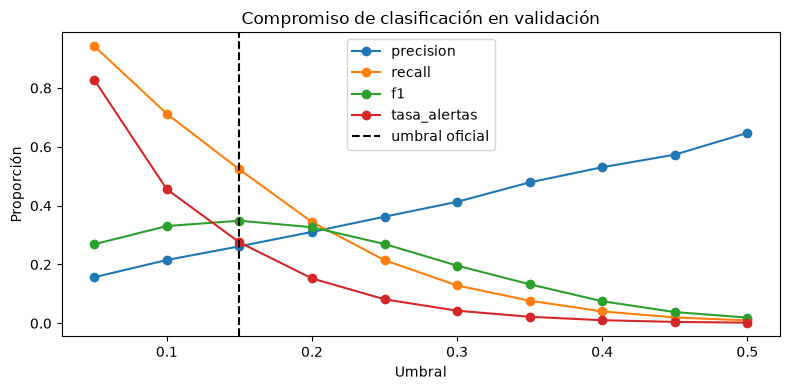

In [5]:
display(umbrales.round(4))
fig, ax = plt.subplots(figsize=(8,4))
for columna in ["precision", "recall", "f1", "tasa_alertas"]:
    ax.plot(umbrales["umbral"], umbrales[columna], marker="o", label=columna)
ax.axvline(resumen["umbral_elegido_en_validacion"], linestyle="--", color="black", label="umbral oficial")
ax.set(xlabel="Umbral", ylabel="Proporción", title="Compromiso de clasificación en validación")
ax.legend()
plt.tight_layout()
plt.show()

## 2. Desempeño territorial — test

La evaluación por comuna revela **heterogeneidad de recall**. Entre las diez comunas con más operaciones, Santiago alcanza **42.0 %**, Las Condes **37.8 %**, Ñuñoa **21.1 %** y Quilicura **16.5 %**. La brecha Santiago–Quilicura es de **25.5 puntos porcentuales**.

Las diferencias indican que el modelo no identifica retrasos con igual sensibilidad en todos los destinos. **No constituyen por sí solas prueba de discriminación injustificada:** pueden intervenir tasas base distintas, composición de rutas, volumen de operaciones y otros factores.

Las comunas con pocos retrasos tienen estimaciones menos estables. Por eso se incorpora `muestra_suficiente_recall` como indicador descriptivo y se evita reajustar el umbral o los hiperparámetros usando resultados del test.


,comuna_destino,operaciones,retrasos,tasa_retrasos,tasa_alertas,precision,recall,muestra_suficiente_recall
0,Santiago,22358,4173,0.1866,0.2159,0.3632,0.4201,True
1,Las Condes,15973,2679,0.1677,0.1815,0.3498,0.3785,True
2,Maipú,14270,2005,0.1405,0.1093,0.3314,0.2579,True
3,Providencia,12868,1981,0.1539,0.1467,0.3506,0.3342,True
4,La Florida,12700,1736,0.1367,0.1111,0.3381,0.2748,True
5,Puente Alto,11299,1706,0.1510,0.1514,0.3413,0.3423,True
6,Ñuñoa,11088,1339,0.1208,0.0767,0.3325,0.2114,True
7,Valparaíso,7924,1208,0.1524,0.1417,0.3411,0.3171,True
8,Quilicura,7911,901,0.1139,0.0630,0.2992,0.1654,True
9,Viña del Mar,7908,1128,0.1426,0.1155,0.3582,0.2899,True


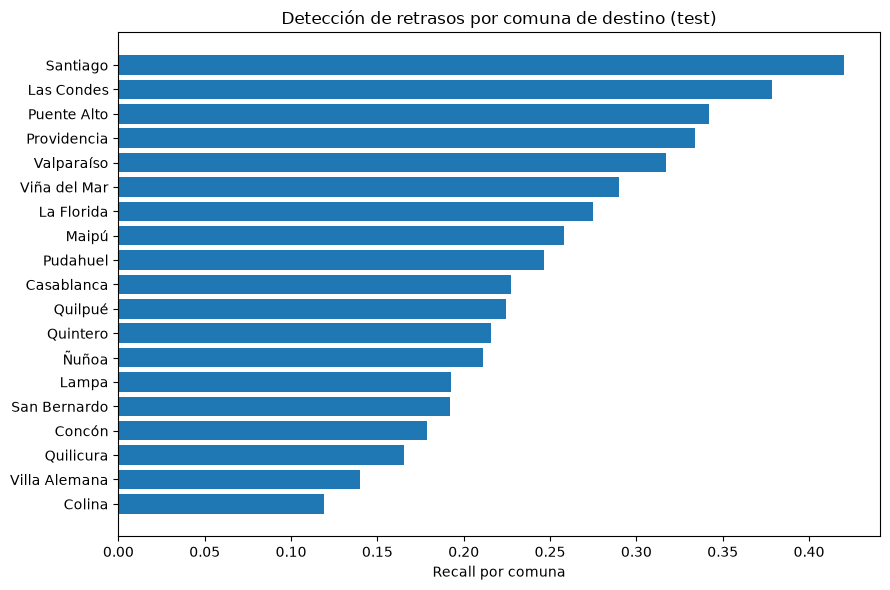

In [6]:
columnas = ["comuna_destino", "operaciones", "retrasos", "tasa_retrasos", "tasa_alertas", "precision", "recall", "muestra_suficiente_recall"]
display(comunas[columnas].round(4))
orden = comunas.sort_values("recall")
fig, ax = plt.subplots(figsize=(9,6))
ax.barh(orden["comuna_destino"], orden["recall"])
ax.set(xlabel="Recall por comuna", title="Detección de retrasos por comuna de destino (test)")
plt.tight_layout()
plt.show()

## 3. Síntesis de evaluación y limitaciones

1. **Selección reproducible:** se compararon dos algoritmos y se eligió XGBoost por desempeño de validación, sin consultar test.
2. **Compromiso operativo:** el umbral oficial 0.15 maximiza F1 en validación; bajar el umbral mejora recall a costa de más alertas.
3. **Errores de clasificación:** el test registra 15.049 retrasos no detectados y 12.776 falsas alarmas; ambos tipos de error deben considerarse en decisiones logísticas.
4. **Variación territorial:** existen diferencias de recall entre comunas, que merecen seguimiento y análisis contextual.
5. **Naturaleza sintética:** las distribuciones y relaciones fueron diseñadas en la simulación; la evaluación no sustituye una validación con datos reales.
6. **Separación temporal:** las métricas de test se registran como evaluación final; no deben emplearse para decidir nuevas variables, umbrales o hiperparámetros sin una nueva evaluación independiente.

**Relación con el objetivo de negocio:** una predicción de retraso no equivale a una reducción del retraso. Para demostrar una disminución del 20 % sería necesario definir intervenciones, costos y una evaluación del efecto de aplicarlas.


## 4. Explicabilidad global SHAP — evidencia H4-T2

Los valores SHAP se calcularon sobre una muestra reproducible de **500 operaciones de validación (julio de 2026)** y se agruparon por predictor original: las columnas de codificación one-hot y los indicadores de datos faltantes se suman por observación antes de calcular la importancia global.

La importancia global se presenta mediante la **media del valor absoluto SHAP** en el margen bruto del XGBoost (**log-odds**). Este valor indica cuánto influye una variable en la salida del modelo, **sin indicar por sí solo la dirección del efecto ni una variación en puntos porcentuales de probabilidad**.

Las mayores importancias obtenidas fueron:
- `es_hora_punta`: **0.4754**.
- `mes`: **0.3586**.
- `duracion_estimada_min`: **0.2315**.
- `comuna_destino`: **0.1710**.
- `experiencia_conductor_anios`: **0.1407**.

Esto muestra un predominio de variables temporales, de planificación y contexto territorial en las predicciones del modelo. No demuestra relaciones causales.

**Precaución sobre `mes`:** toda la muestra SHAP procede de **julio**, por lo que `mes = 7` en todas las observaciones. Su importancia y contribución reflejan cómo el modelo utiliza ese valor dentro de su representación aprendida; **esta visualización no permite concluir que el riesgo crezca progresivamente a medida que avanzan los meses**. Para estudiar variaciones entre meses se requeriría un análisis específico con registros de varios períodos, separado de la selección y evaluación final.


Muestra: 500 | Período: validacion (julio 2026)
Escala: log-odds / margen bruto de XGBoost; NO puntos porcentuales de probabilidad


,variable,valor
0,es_hora_punta,0.4754
1,mes,0.3586
2,duracion_estimada_min,0.2315
3,comuna_destino,0.1710
4,experiencia_conductor_anios,0.1407
5,distancia_km,0.1195
6,tipo_vehiculo,0.0979
7,dia_semana,0.0791
8,franja_horaria,0.0499
9,n_paquetes,0.0396


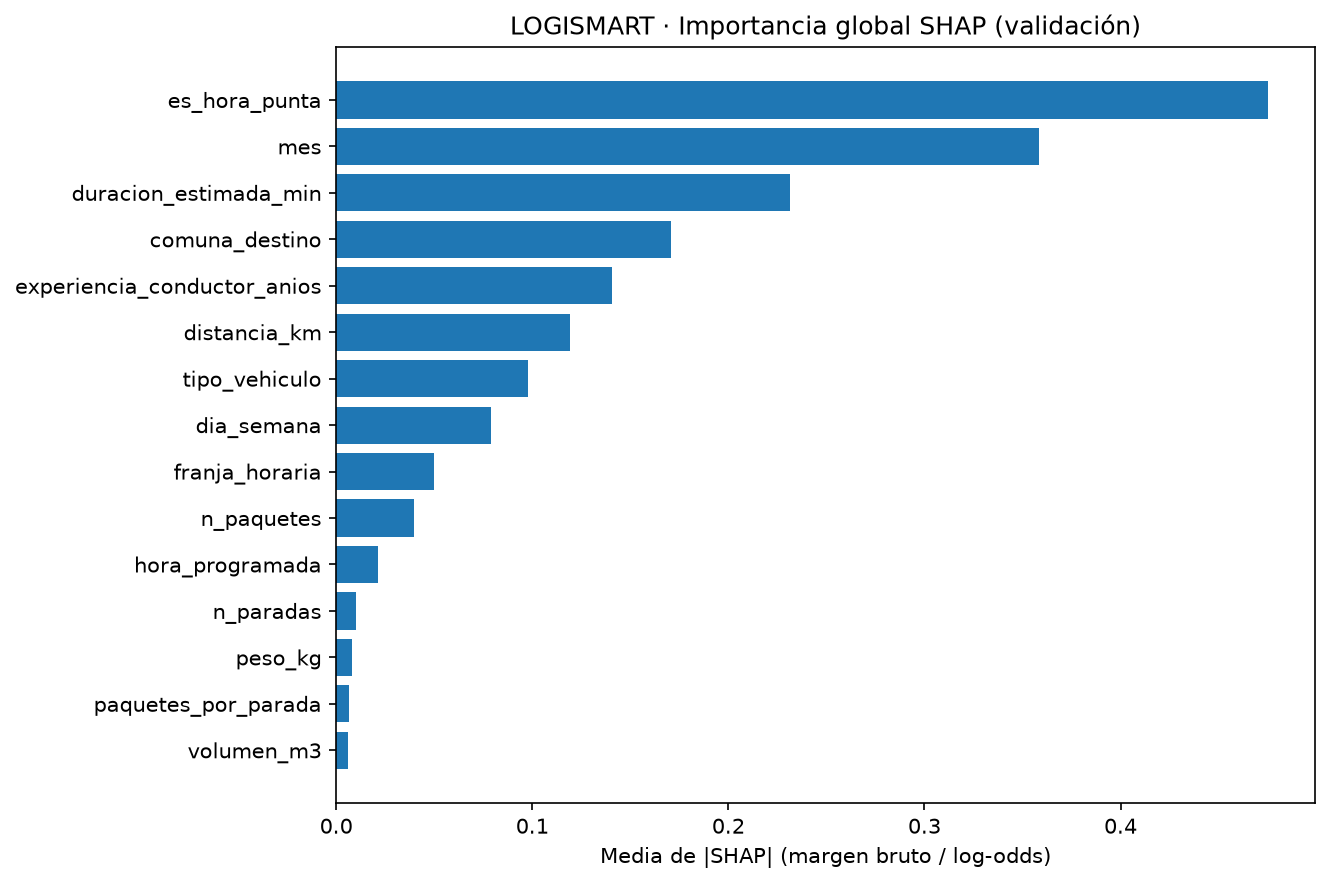

In [7]:
from IPython.display import Image, display
ruta_shap = resultados_dir / "explicabilidad_shap.json"
ruta_fig = graficos_dir / "importancia_shap.png"
if not ruta_shap.exists() or not ruta_fig.exists():
    raise FileNotFoundError("Ejecuta primero: python main.py --proceso explicar")
explicacion = json.loads(ruta_shap.read_text(encoding="utf-8"))
print("Muestra:", explicacion["numero_operaciones"], "| Período:", explicacion["conjunto_explicado"])
print("Escala:", explicacion["escala_shap"])
display(pd.DataFrame(explicacion["importancia_global_media_abs_shap"]).head(15).round(4))
display(Image(filename=str(ruta_fig)))

### Explicación local y lectura crítica

Una contribución SHAP positiva desplaza el **margen bruto** de XGBoost hacia un mayor riesgo y una negativa lo desplaza hacia un menor riesgo. Los valores están expresados en **log-odds**, no en porcentajes de probabilidad ni en efectos causales.

En la ejecución documentada, el ejemplo local elegido corresponde a la operación con **mayor probabilidad estimada dentro de la muestra de 500 registros**. Esa elección sirve para ilustrar cómo funciona el modelo, pero **no representa una operación promedio** ni una prueba de que sus características causen retrasos.


In [8]:
ejemplo = explicacion["ejemplo_local"]
print("Probabilidad predicha:", round(ejemplo["probabilidad_predicha"], 4))
display(pd.DataFrame(ejemplo["top_atribuciones_por_variable"]).head(12).round(4))

Probabilidad predicha: 0.6035


,variable,shap
0,duracion_estimada_min,0.6921
1,es_hora_punta,0.5780
2,distancia_km,0.3373
3,mes,0.3328
4,comuna_destino,0.2888
5,dia_semana,0.2618
6,experiencia_conductor_anios,0.2455
7,tipo_vehiculo,-0.0907
8,n_paquetes,0.0430
9,franja_horaria,0.0313


### Interpretación de la importancia SHAP global

`es_hora_punta` tiene la mayor influencia media; le siguen `mes` y `duracion_estimada_min`. También destacan `comuna_destino`, `experiencia_conductor_anios`, `distancia_km` y `tipo_vehiculo`. En cambio, `peso_kg`, `volumen_m3` y `paquetes_por_parada` presentan aportes mucho menores en esta ejecución.

Varias características están relacionadas entre sí: `es_hora_punta` se deriva de `hora_programada`, y la duración estimada se relaciona con distancia y número de paradas. Por tanto, la atribución de importancia puede concentrarse en algunas variables correlacionadas o derivadas. **No corresponde eliminar predictores únicamente por su menor importancia SHAP**.

El mes es particularmente sensible a la construcción del dataset sintético: el generador incorpora una evolución temporal del riesgo. Estas explicaciones deben interpretarse como un análisis del **comportamiento del modelo entrenado**, no como descubrimientos causales sobre transporte real.


## 5. SHAP beeswarm y waterfall — evidencia H4-T2

Los gráficos se generan en `src/explicabilidad.py` y se guardan en `output/graficos/`. El notebook únicamente los visualiza.

**Beeswarm:** cada punto es una operación de validación. El eje horizontal expresa la contribución SHAP al margen bruto del modelo. A la **derecha de cero** la variable aumenta el riesgo predicho y a la **izquierda** lo reduce. En variables numéricas, rojo representa valores relativamente altos y azul valores bajos; las variables categóricas se muestran en gris porque no existe una escala cuantitativa natural de color.

**Waterfall:** descompone la predicción de una operación individual. Parte del valor base **E[f(X)]**, suma las contribuciones positivas y negativas de las variables y llega a **f(x)**. Ambos extremos están en log-odds; para expresarlos como probabilidad hay que aplicar la función sigmoide.

**Interpretación de `mes`:** como las 500 operaciones proceden de julio, todos los puntos tienen el mismo mes. La dispersión de contribuciones SHAP para `mes` **no demuestra diferencias entre meses**, ni que un mes posterior aumente necesariamente los retrasos.


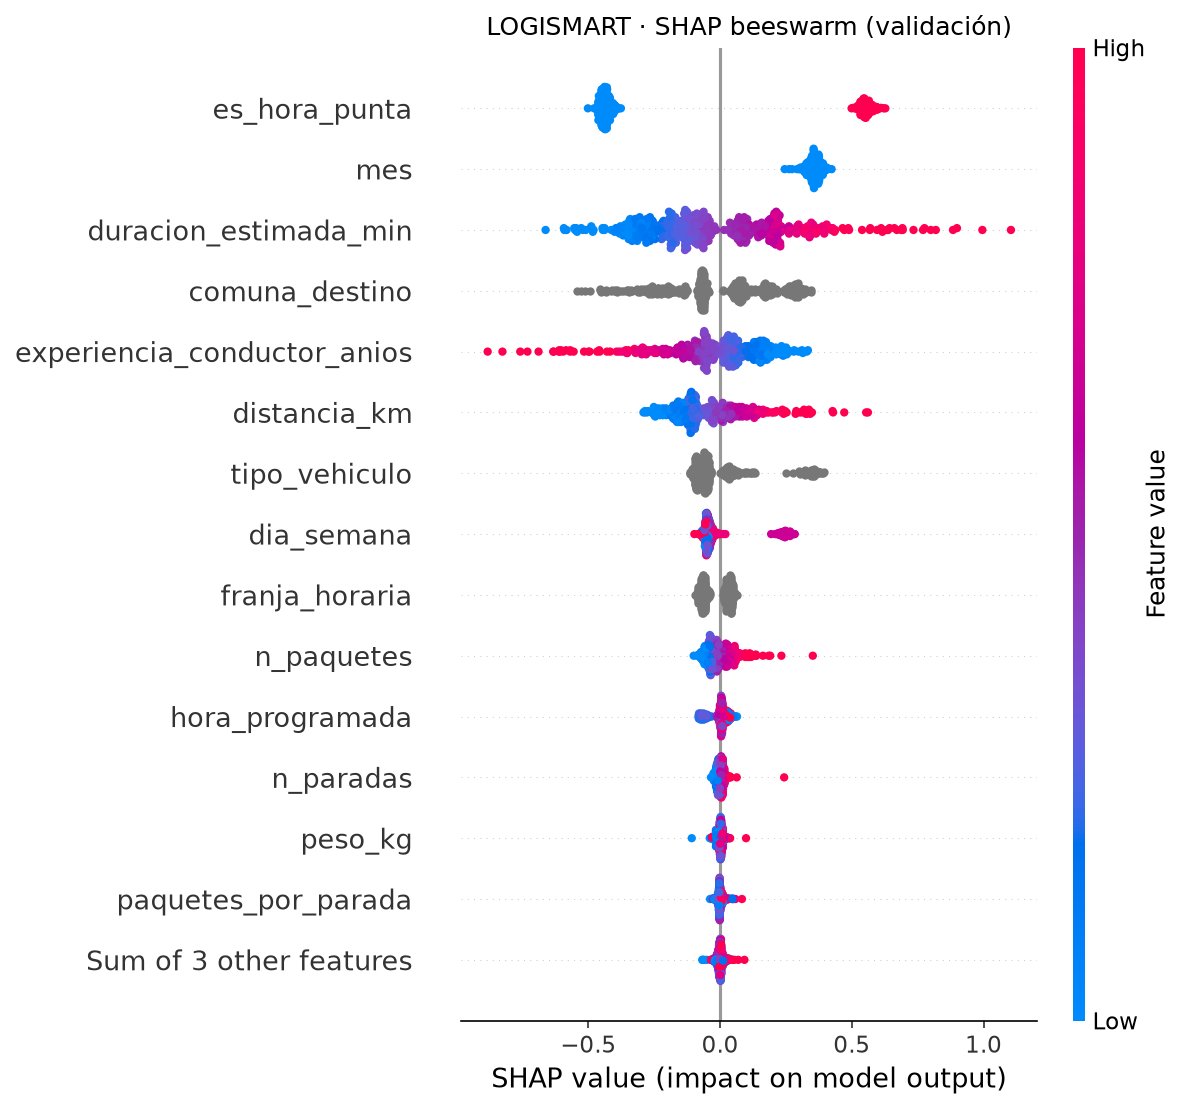

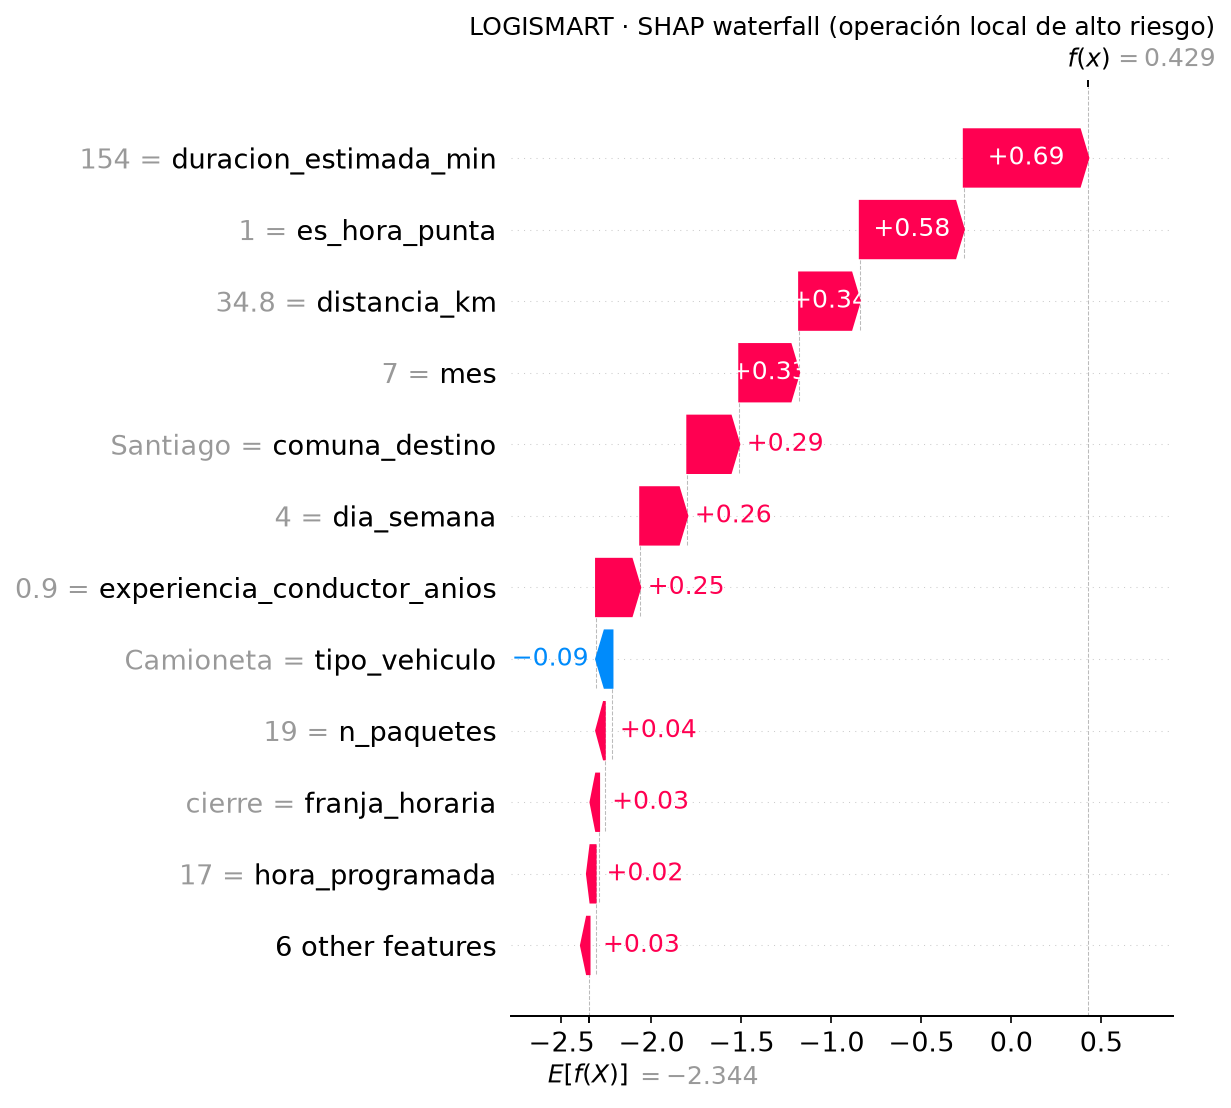

In [9]:
from IPython.display import Image, display

for nombre in ["beeswarm_shap.png", "waterfall_shap.png"]:
    ruta = graficos_dir / nombre
    if not ruta.exists():
        raise FileNotFoundError(f"No existe {ruta}. Ejecuta python main.py --proceso explicar")
    display(Image(filename=str(ruta)))

### Interpretación del beeswarm

En la ejecución documentada se observan los siguientes patrones:
- **Hora punta:** `es_hora_punta = 1` aparece principalmente con contribuciones positivas; `0`, con negativas. El modelo asocia la condición de hora punta con una mayor predicción de riesgo.
- **Duración estimada y distancia:** los valores altos tienden a desplazarse hacia SHAP positivo y los bajos hacia SHAP negativo.
- **Experiencia del conductor:** una experiencia mayor tiende a mostrar contribuciones negativas; en la muestra, menor experiencia se asocia con un riesgo predicho mayor.
- **Comuna y tipo de vehículo:** sus puntos grises permiten apreciar diferencias en contribuciones, pero el color no indica un orden de categorías.
- **Mes:** toda la muestra pertenece a julio. Que SHAP sea positivo para `mes = 7` no prueba una tendencia creciente entre meses.

La interpretación describe asociaciones **aprendidas por XGBoost** dentro de un dataset simulado; no establece que intervenir sobre una variable produzca automáticamente el cambio predicho.

### Interpretación del waterfall: operación de alto riesgo

El ejemplo mostrado corresponde a una operación con **154 minutos** de duración estimada, **34.8 km** de recorrido, despacho programado a las **17:00**, destino **Santiago**, **19 paquetes** y **0.9 años** de experiencia del conductor.

El modelo parte de un margen base aproximado de **−2.344** y termina en **f(x) = 0.429**. Aplicando la sigmoide, este último valor equivale aproximadamente a **60.6 % de probabilidad predicha de retraso**: supera el umbral oficial de **15 %** y, por tanto, se clasifica como operación de riesgo.

Las mayores contribuciones positivas son **duración estimada (+0.69)**, **hora punta (+0.58)**, **distancia (+0.34)**, **mes (+0.33)** y **comuna destino (+0.29)**. La categoría **Camioneta** muestra una contribución negativa pequeña (aproximadamente **−0.09**). Estas contribuciones son cambios en el margen **log-odds**, no en puntos porcentuales.

**Límites de la interpretación local:** es un ejemplo intencionalmente seleccionado por alta probabilidad dentro de la muestra, no un caso representativo de todas las entregas. La descomposición explica cómo el modelo produjo su estimación y no constituye evidencia de que una modificación operativa específica evite el retraso.

### Cierre de H4-T2

El análisis reúne tres niveles complementarios: **importancia global** (magnitud media), **beeswarm** (dirección y dispersión) y **waterfall** (explicación individual). En conjunto, aporta trazabilidad a las decisiones del modelo, manteniendo las limitaciones propias de datos sintéticos y de la atribución predictiva.


## 6. H4-T3 — Optimización de hiperparámetros

La búsqueda de configuraciones de **Random Forest y XGBoost** se implementa en `src/optimizacion.py` y se ejecuta con `python main.py --proceso optimizar`. El notebook **no realiza la búsqueda**: presenta sus resultados guardados.

**Diseño metodológico:** se utiliza `RandomizedSearchCV` con dos folds cronológicos expansivos **dentro del entrenamiento**, seleccionando hiperparámetros por PR-AUC. Se compara cada configuración inicial con la optimizada utilizando el **mismo subconjunto de entrenamiento**. Julio de 2026 permite una comparación externa; agosto–septiembre (test) **no interviene** en esta actividad.

**Eficiencia:** se registra tiempo de búsqueda, tiempo de ajuste y pico de asignaciones de memoria Python (`tracemalloc`, que no mide toda la RAM del proceso ni la memoria nativa de XGBoost).

**Importante:** la configuración optimizada es **candidata**; el modelo oficial serializado no se sustituye automáticamente. Una mejora en un subconjunto o en CV no garantiza mejor rendimiento futuro.

In [10]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display

base = Path.cwd()
if base.name == "notebooks":
    base = base.parent
ruta_opt = base / "output" / "resultados" / "optimizacion_hiperparametros.json"
if not ruta_opt.exists():
    raise FileNotFoundError("Ejecuta primero: python main.py --proceso optimizar")
opt = json.loads(ruta_opt.read_text(encoding="utf-8"))
print("Estrategia:", opt["estrategia"])
print("Métrica de búsqueda:", opt["metrica_busqueda"])
print("Muestra train:", opt["registros_train_usados"], "de", opt["registros_train_disponibles"])

filas = []
for modelo, info in opt["resultados"].items():
    for version, met in info["validacion_julio"].items():
        e = info["eficiencia"]
        prefijo = "base" if version == "base" else "optimizado"
        filas.append({
            "Modelo": modelo,
            "Versión": version,
            "PR-AUC julio": met["pr_auc"],
            "ROC-AUC julio": met["roc_auc"],
            "Segundos ajuste": e[f"{prefijo}_segundos_fit"],
            "Memoria Python pico (MB)": e[f"{prefijo}_pico_memoria_python_mb"],
            "PR-AUC mejor CV": info["pr_auc_cv_mejor"] if version == "optimizado" else None,
        })
display(pd.DataFrame(filas).round(4))
for modelo, info in opt["resultados"].items():
    print(f"\n{modelo} — mejor configuración:\n{info['hiperparametros_elegidos']}")
    print("Tiempo total de búsqueda:", round(info["eficiencia"]["busqueda_segundos"], 1), "segundos")
    display(pd.DataFrame(info["configuraciones_cv"]).drop(columns=["parametros"]).round(4))

Estrategia: RandomizedSearchCV con dos folds mensuales expansivos dentro de train
Métrica de búsqueda: PR-AUC (average_precision) de folds en train
Muestra train: 100000 de 825299


,Modelo,Versión,PR-AUC julio,ROC-AUC julio,Segundos ajuste,Memoria Python pico (MB),PR-AUC mejor CV
0,Random Forest,base,0.2803,0.6939,7.4019,97.4186,NaN
1,Random Forest,optimizado,0.2773,0.6927,4.8578,96.5494,0.2330
2,XGBoost,base,0.2815,0.6996,5.1902,96.5502,NaN
3,XGBoost,optimizado,0.2881,0.7018,4.5691,96.5499,0.2383



Random Forest — mejor configuración:
{'modelo__n_estimators': 80, 'modelo__min_samples_leaf': 4, 'modelo__max_features': 'sqrt', 'modelo__max_depth': 8}
Tiempo total de búsqueda: 21.1 segundos


,pr_auc_cv_media,pr_auc_cv_desv,segundos_fit_cv_medio,ranking
0,0.2330,0.0210,1.5229,1
1,0.2318,0.0223,2.1017,2
2,0.2318,0.0231,4.7266,3
3,0.2300,0.0228,1.9120,4



XGBoost — mejor configuración:
{'modelo__subsample': 0.7, 'modelo__n_estimators': 160, 'modelo__min_child_weight': 1, 'modelo__max_depth': 3, 'modelo__learning_rate': 0.06, 'modelo__colsample_bytree': 0.85}
Tiempo total de búsqueda: 12.5 segundos


,pr_auc_cv_media,pr_auc_cv_desv,segundos_fit_cv_medio,ranking
0,0.2383,0.0225,1.4838,1
1,0.2346,0.0239,1.9022,2
2,0.2329,0.0229,1.2385,3
3,0.2310,0.0199,1.4864,4


### Interpretación de resultados — H4-T3 (ejecución principal)

Se ejecutó `RandomizedSearchCV` con **4 configuraciones por algoritmo** y **2 folds temporales expansivos** (hasta abril → mayo y hasta mayo → junio de 2026). La búsqueda utilizó **100.000 de las 825.299 operaciones de entrenamiento disponibles** y optimizó **PR-AUC (average precision)**. El conjunto de **julio de 2026 (74.766 operaciones)** se usó para comparar las configuraciones base y candidatas; el conjunto de prueba de agosto y septiembre **no se consultó para esta tarea**.

**Comparación en validación externa (julio):**

| Modelo | PR-AUC base | PR-AUC optimizado | ROC-AUC base → optimizado | Tiempo de ajuste base → optimizado |
|---|---:|---:|---:|---:|
| Random Forest | 0.2803 | 0.2773 | 0.6939 → 0.6927 | 7.40 s → 4.86 s |
| XGBoost | 0.2815 | **0.2881** | 0.6996 → **0.7018** | 5.19 s → **4.57 s** |

En Random Forest la optimización disminuyó ligeramente el PR-AUC (−0.0029 puntos absolutos), aunque redujo el tiempo de ajuste. Para XGBoost, PR-AUC aumentó **0.0065 puntos absolutos** (aproximadamente **2.31 % relativo**) y el tiempo de ajuste disminuyó aproximadamente **12 %**. Estos tiempos describen el ajuste de cada modelo, **sin incluir la búsqueda**: la búsqueda empleó **21.08 s en Random Forest** y **12.51 s en XGBoost**.

**Mejores hiperparámetros por PR-AUC promedio en CV:**

- **Random Forest:** `n_estimators=80`, `max_depth=8`, `min_samples_leaf=4`, `max_features='sqrt'` (**PR-AUC CV: 0.2330**).
- **XGBoost:** `n_estimators=160`, `max_depth=3`, `learning_rate=0.06`, `subsample=0.7`, `colsample_bytree=0.85`, `min_child_weight=1` (**PR-AUC CV: 0.2383**).

**Decisión:** XGBoost optimizado es el **mejor candidato dentro de este experimento de 100.000 registros**, con mejor equilibrio entre PR-AUC en julio y tiempo de ajuste. **Se conserva el XGBoost oficial** entrenado con 825.299 registros (`models/modelo_logismart.joblib`): su PR-AUC previo de validación fue 0.2898, levemente superior a 0.2881, pero las ejecuciones no son directamente comparables por el tamaño de entrenamiento. No corresponde sustituir el modelo oficial sin una comparación controlada con la configuración optimizada sobre el mismo volumen y protocolo.

**Limitaciones y cautelas:** la búsqueda exploró solamente cuatro combinaciones por modelo; por tanto, no garantiza encontrar el óptimo global. El pico de memoria informado por `tracemalloc` (~96–97 MB) refleja asignaciones Python y **no es una medición de RAM total** (no incorpora necesariamente memoria nativa de XGBoost). Las métricas se obtuvieron sobre **datos sintéticos**: no prueban mejoras operacionales reales. La selección de hiperparámetros se basó en CV interna; julio se usó para comparación externa, no para elegir una configuración en cada búsqueda. La predicción en test queda reservada al protocolo final.

**Evidencias:** `src/optimizacion.py`, `output/resultados/optimizacion_hiperparametros.json` y `output/resultados/comparacion_optimizacion.csv`. El notebook únicamente **lee y explica** esos resultados; no duplica el procedimiento de entrenamiento ni búsqueda.

## 7. H4-T4 — Análisis preliminar de diferencias territoriales

Este diagnóstico descriptivo se genera con `python main.py --proceso sesgos`, a partir de la auditoría existente (`output/resultados/auditoria_comunas_test.json`). **No entrena ni recalcula predicciones** y no selecciona umbrales sobre test.

Se comparan por comuna: volumen de operaciones, tasa de retrasos, tasa de alertas, precision, recall y FPR; se añaden intervalos Wilson aproximados al 95 % para recall, usando como denominador el número de retrasos, no todas las operaciones.

**Limitación:** diferencias entre comunas son señales que ameritan investigación, no pruebas concluyentes de sesgo injusto. Menor representación no implica automáticamente peor desempeño; además, las tasas base y complejidad operativa pueden variar. Los intervalos asumen independencia aproximada. No se propone sancionar conductores ni modificar umbrales por resultados de test.

**Mitigación propuesta:** obtener más datos representativos por comuna, revisar calidad/cobertura y covariables, y evaluar cualquier rebalanceo exclusivamente con train y validación temporal. La auditoría exhaustiva corresponde a H5-T3.


,comuna_destino,operaciones,retrasos,recall,recall_ic95_inf,recall_ic95_sup,precision,fpr,muestra_baja_relativa
0,Santiago,22358,4173,0.420,0.405,0.435,0.363,0.169,False
1,Las Condes,15973,2679,0.378,0.360,0.397,0.350,0.142,False
2,Maipú,14270,2005,0.258,0.239,0.277,0.331,0.085,False
3,Providencia,12868,1981,0.334,0.314,0.355,0.351,0.113,False
4,La Florida,12700,1736,0.275,0.254,0.296,0.338,0.085,False
5,Puente Alto,11299,1706,0.342,0.320,0.365,0.341,0.117,False
6,Ñuñoa,11088,1339,0.211,0.190,0.234,0.333,0.058,False
7,Valparaíso,7924,1208,0.317,0.291,0.344,0.341,0.110,False
8,Quilicura,7911,901,0.165,0.143,0.191,0.299,0.050,False
9,Viña del Mar,7908,1128,0.290,0.264,0.317,0.358,0.086,False


Brecha descriptiva recall: 0.300910491700284


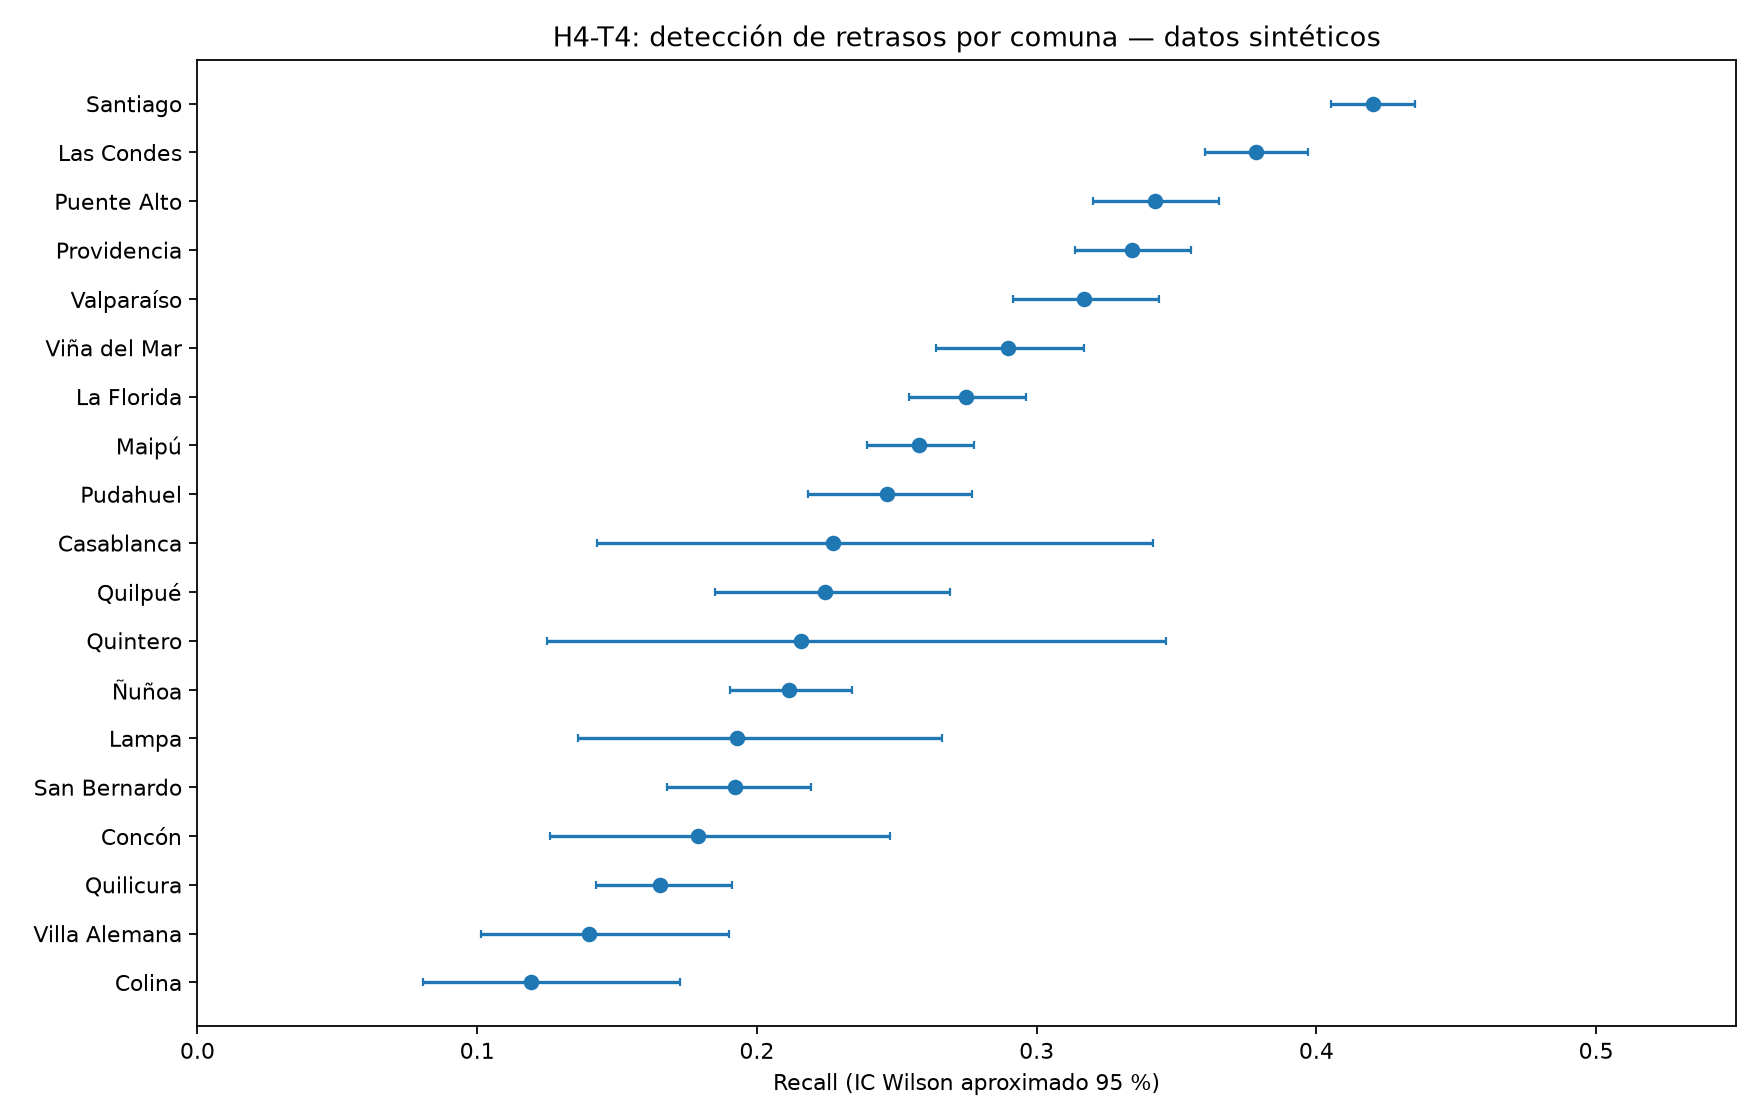

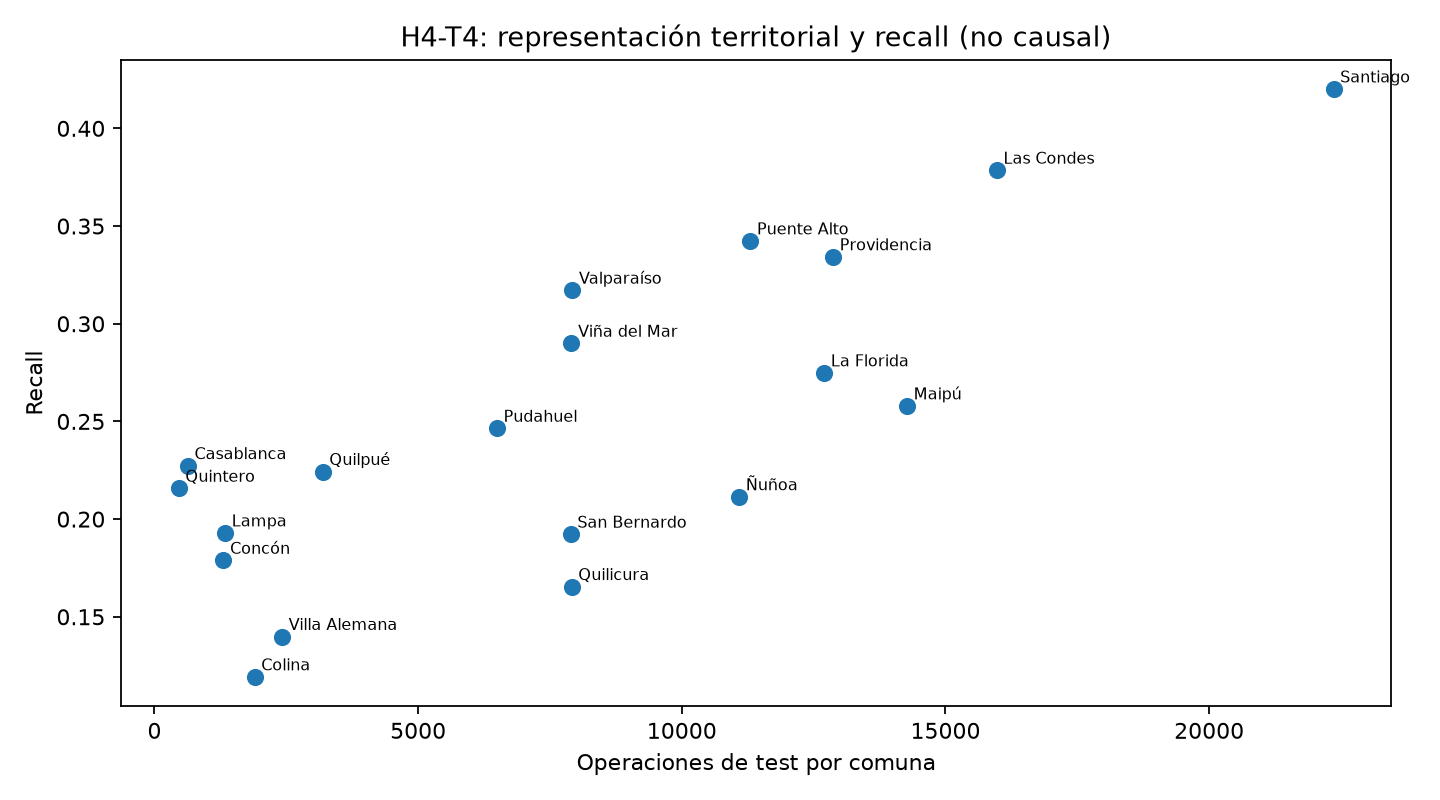

In [11]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
base = Path.cwd()
if base.name == "notebooks": base = base.parent
ruta = base / "output/resultados/diagnostico_sesgos_comunas.csv"
informe_ruta = base / "output/resultados/diagnostico_sesgos.json"
if not ruta.exists() or not informe_ruta.exists():
    raise FileNotFoundError("Ejecuta primero: python main.py --proceso sesgos")
tabla_sesgos = pd.read_csv(ruta)
resumen_sesgos = json.loads(informe_ruta.read_text(encoding="utf-8"))
display(tabla_sesgos[["comuna_destino","operaciones","retrasos","recall","recall_ic95_inf","recall_ic95_sup","precision","fpr","muestra_baja_relativa"]].round(3))
print("Brecha descriptiva recall:", resumen_sesgos["brecha_recall_comunas_con_al_menos_30_retrasos"])
for nombre in ["sesgos_recall_comunas.png","sesgos_representacion_recall.png"]:
    display(Image(filename=str(base / "output/graficos" / nombre)))


### Interpretación de resultados y cierre — H4-T4

**Alcance.** Se analizaron **149.935 operaciones sintéticas**, de las cuales **21.795** presentaron retraso, distribuidas en **19 comunas** del conjunto de prueba de agosto–septiembre de 2026. Con el umbral oficial de **0.15** (fijado previamente en validación), el modelo alcanzó **recall global de 30.95 %**, **precision de 34.56 %** y **FPR de 9.97 %**. Esta tarea describe resultados existentes: **no reentrena, no ajusta umbrales ni selecciona el modelo usando test**.

**Disparidades territoriales.** El recall varía entre **42.01 % en Santiago** (4.173 retrasos; 1.753 detectados) y **11.92 % en Colina** (193 retrasos; 23 detectados), una brecha descriptiva de **30.09 puntos porcentuales**. En comunas con varios miles de operaciones persisten resultados bajos: **Ñuñoa 21.14 %** (1.056 retrasos sin alerta) y **Quilicura 16.54 %** (752 retrasos sin alerta). Las diferencias no se limitan a los grupos pequeños. En Santiago, a su vez, la **FPR es 16.90 %**, frente a **4.98 % en Quilicura**: aumentar alertas sin controlar falsos positivos puede incrementar la carga operativa.

**Representación y desbalance.** Entre las 19 comunas se observó una correlación **Spearman = 0.70** entre cantidad de operaciones y recall: asociación descriptiva positiva, **no causal**, que no prueba que la menor representación sea el motivo de menor detección. También varían las tasas base: **18.66 %** de retrasos en Santiago y **11.39 %** en Quilicura. Es necesario considerar diferencias de composición (por ejemplo, distancias y horarios) antes de atribuir disparidades a una causa concreta. La relación con el tamaño tampoco es uniforme: **Quintero** cuenta con 460 operaciones y recall 21.57 %, mientras **Quilicura** tiene 7.911 operaciones y recall 16.54 %.

**Incertidumbre.** Los intervalos de Wilson al 95 % se estiman con el **número de retrasos** como denominador del recall. Son más amplios cuando hay menos casos positivos: **Quintero ~12.49 %–34.63 %** (51 retrasos), frente a **Santiago ~40.52 %–43.51 %** (4.173 retrasos). Deben interpretarse como aproximaciones, porque las operaciones podrían no ser independientes (rutas o conductores compartidos). Todos los grupos analizados tienen al menos 30 retrasos; la etiqueta `muestra_baja_relativa` compara su representación con la mediana de operaciones, **no invalida automáticamente sus métricas**.

**Riesgos y mitigaciones recomendadas:**

1. Revisar calidad y cobertura de datos por **comuna y mes**, priorizando comunas subrepresentadas, sin suponer que añadir filas resolverá el problema por sí solo.
2. Investigar **falsos negativos** y **falsos positivos** en Ñuñoa, Quilicura y Santiago; contrastar distancias, horarios y tasas base de retraso.
3. Monitorear **recall, precision, FPR e intervalos de incertidumbre** por comuna, no solamente la métrica global.
4. Evaluar posibles ajustes de ponderación, muestreo o calibración **solo en entrenamiento y validación cronológica**; no elegir modificaciones con base en el test ya inspeccionado.
5. Utilizar las alertas exclusivamente como **apoyo a decisiones operacionales**, sin evaluaciones o sanciones automáticas de conductores.

**Conclusión de H4-T4.** Se identificaron **diferencias territoriales sustanciales y un riesgo potencial de disparidad en la detección**, junto con una asociación positiva entre representación y recall. **No se ha demostrado discriminación ni causalidad**, y los datos son sintéticos. La evaluación más exhaustiva de equidad y de eventuales mitigaciones se reserva para **H5-T3**, evitando duplicar análisis y sin afirmar mejoras operacionales reales.

**Evidencias:** `src/sesgos.py`, `output/resultados/diagnostico_sesgos.json`, `output/resultados/diagnostico_sesgos_comunas.csv`, `output/graficos/sesgos_recall_comunas.png` y `output/graficos/sesgos_representacion_recall.png`.
